## 1 Data Acquisation and EDA 


In [1]:
#import necessary libraries
import os 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# ensure output directories exist
os.makedirs("../data", exist_ok=True)
os.makedirs("../visualizations", exist_ok=True)

In [2]:
#Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#### Raw Data Collection

In [3]:
#fetch dataset (ID: 45 is UCI Heart disease dataset)
heart_disease = fetch_ucirepo(id=45)

#Extract feature matrix and target vector
X = heart_disease.data.features
y = heart_disease.data.targets

#Display initial metadata and shape
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
X.head()

Feature shape: (303, 13)
Target shape: (303, 1)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


### 3. Cleaning and Binary Target Transformation

In [4]:
#combine features and target into a single DataFrame for easier analysis
df = pd.concat([X,y], axis=1)

#convert target num to binary labels (0: No Heart Disease, 1: Heart Disease)
df['target'] = df['num'].apply(lambda x: 1 if x > 0 else 0)

In [5]:
#check missing value count before cleaning
print("Missing values before cleaning:\n", df.isnull().sum()[df.isnull().sum() > 0])


Missing values before cleaning:
 ca      4
thal    2
dtype: int64


In [6]:
df_cleaned = df.dropna().copy()

In [7]:
print("Original row count:", df.shape[0])
print("Cleaned row count:", df_cleaned.shape[0])

Original row count: 303
Cleaned row count: 297


In [8]:
# save cleaning data for modelling phase
df_cleaned.to_csv("../data/heart_disease_cleaned.csv", index=False)
print("Cleaned data saved to ../data/heart_disease_cleaned.csv")

Cleaned data saved to ../data/heart_disease_cleaned.csv


#### 4. Class Balance Visualization


C:\Users\phema\AppData\Local\Temp\ipykernel_14320\808846560.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='target', data=df_cleaned, palette=['#FF6F61', '#6B5B95'])


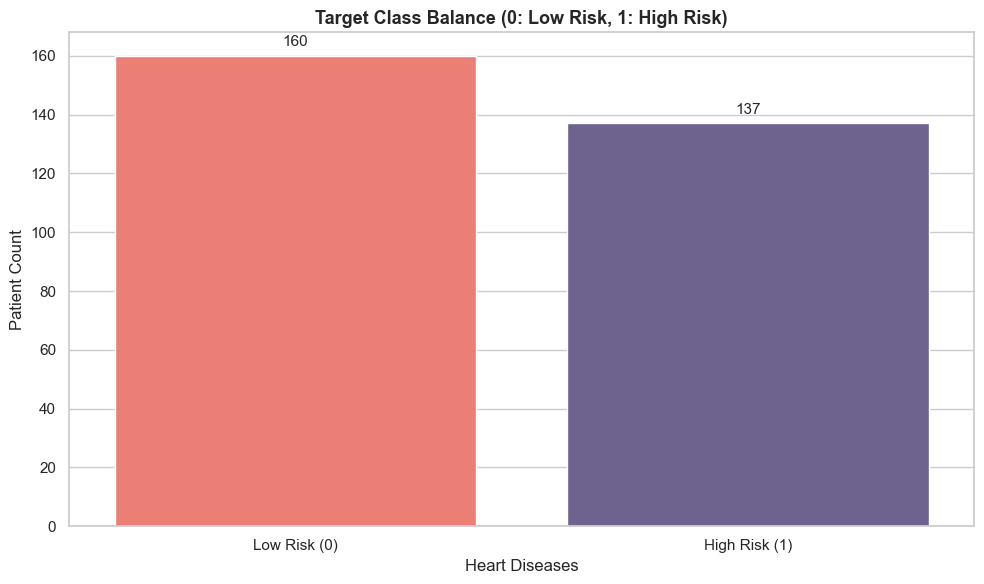

In [9]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(x='target', data=df_cleaned, palette=['#FF6F61', '#6B5B95'])
plt.title('Target Class Balance (0: Low Risk, 1: High Risk)', fontsize=13, fontweight='bold')
plt.xlabel('Heart Diseases')
plt.ylabel("Patient Count")
plt.xticks(ticks=[0, 1], labels=['Low Risk (0)', 'High Risk (1)'])

#annotating count on top of the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', xytext=(0,5), textcoords='offset points', fontsize=11)

plt.tight_layout()
plt.savefig("../visualizations/target_class_balance.png", dpi=300)
plt.show()

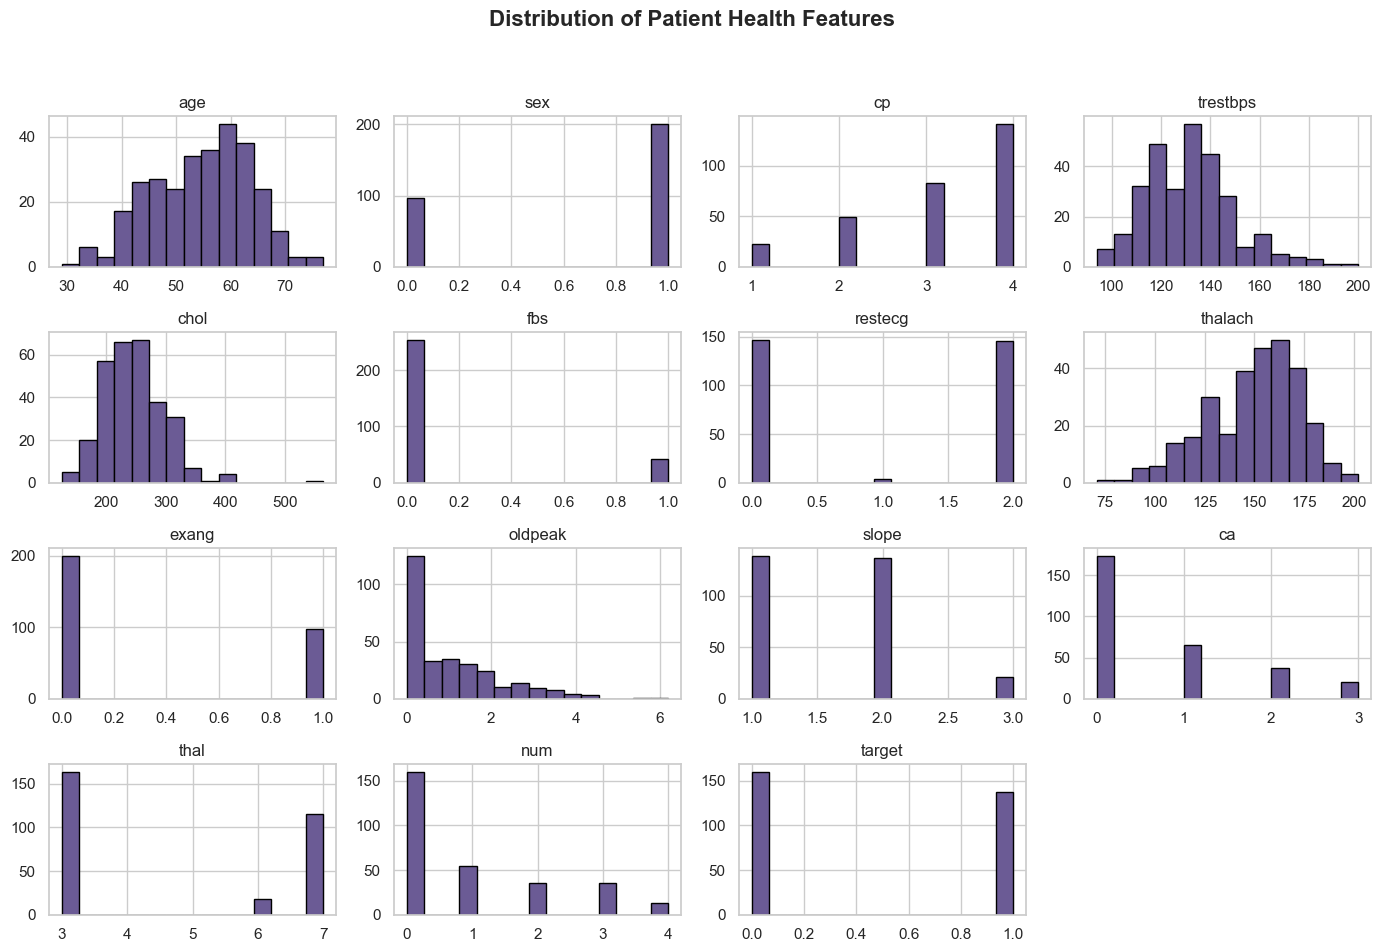

In [10]:
## Feature Histogram

df_cleaned.hist(figsize=(14, 10), bins=15, color = '#6b5b95', edgecolor='black')
plt.suptitle('Distribution of Patient Health Features', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("../visualizations/feature_histograms.png", dpi=900)
plt.show()

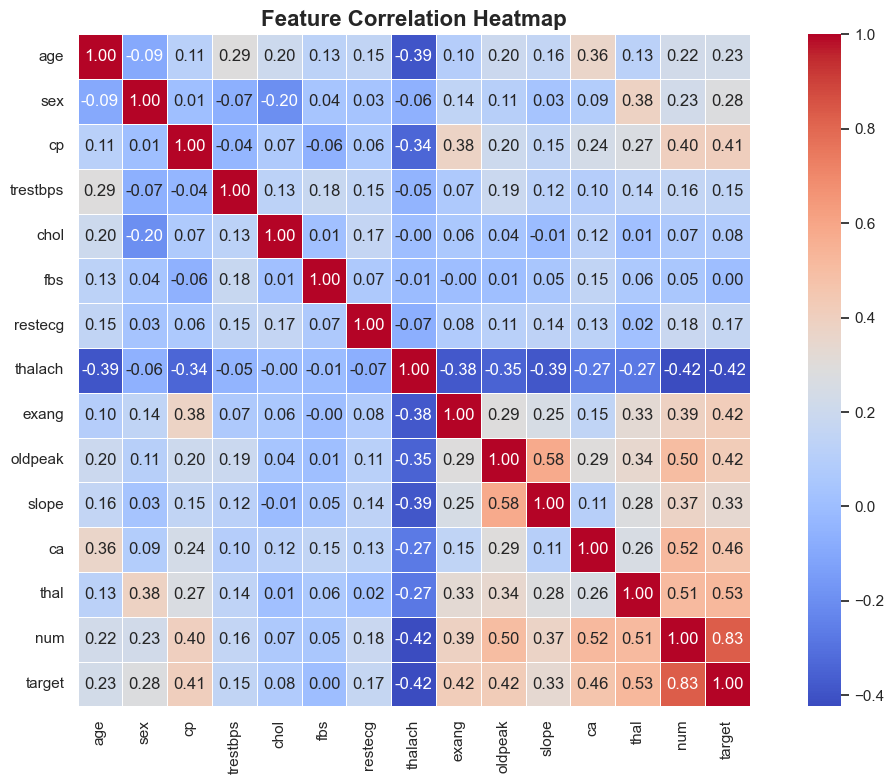

In [11]:
# Feature Correlation Heatmap

plt.figure(figsize=(12, 8))
corr_matrix = df_cleaned.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("../visualizations/feature_correlation_heatmap.png", dpi=900)
plt.show()